# Full glass: LQR vs MPC on a wheeled biped

*How Robots Think*

[Upkie](https://github.com/upkie/upkie), an open-source wheeled biped, carries a full glass of water and its goal
jumps 2 m ahead. Same robot, same linear model, same weights $Q$ and $R$. Only the controller changes:

| controller | what it does |
|---|---|
| **LQR** | $u = -K(x - x_\mathrm{ref})$, $K$ from the discrete Riccati equation |
| **LQR, capped** | the same command, clipped to $\lvert u\rvert \le 0.7$ m/s² after the fact |
| **LQR, retuned** | $R = 1$ and more velocity weight: slow enough to stay near 0.7 m/s² without a cap |
| **MPC** | predicts the next second with the same model and plans within $\lvert u_k\rvert \le 0.7$ m/s² |

Physics: MuJoCo at 1 kHz on Upkie's official model; balancers at 200 Hz. The four simulations take a few seconds
on a laptop CPU, and the notebook shows them side by side.

**The water is not simulated**: the glass and its water are one rigid body. What decides a spill is what the water
*feels*: gravity in the glass frame, tilted by the glass's own acceleration. We measure the angle between that felt
gravity and the glass axis.

In [1]:
# Colab or a fresh environment
%pip install -q "mujoco>=3.17" scipy matplotlib mediapy

In [2]:
import ctypes.util, io, math, os, re, sys, tempfile, time, urllib.request, zipfile
import xml.etree.ElementTree as ET
from pathlib import Path

# Off-screen rendering of the simulation. On Linux, EGL renders on the GPU even on a desktop (on a laptop the default
# backend can land on the integrated GPU or in software, 10 to 100 times slower). Chosen before MuJoCo is imported.
if sys.platform.startswith("linux") and ctypes.util.find_library("EGL"):
    os.environ.setdefault("MUJOCO_GL", "egl")

import matplotlib.pyplot as plt
import mujoco
import numpy as np
from scipy.linalg import solve_discrete_are

# Upkie's official description (URDF and meshes, Apache-2.0; wheel tyre mesh CC BY 4.0), pinned revision.
UPKIE_REV = "94735fbe6137276a41de0ff4cc04d2e533fa9e33"
UPKIE_DIR = Path(f"upkie_description-{UPKIE_REV}")
if not UPKIE_DIR.exists():
    url = f"https://github.com/upkie/upkie_description/archive/{UPKIE_REV}.zip"
    with urllib.request.urlopen(url) as response:
        zipfile.ZipFile(io.BytesIO(response.read())).extractall()

G = 9.81                  # m/s²
DT = 0.001                # physics step: Upkie's spine runs at 1 kHz
CONTROL_EVERY = 5         # the balancer runs every 5 physics steps (200 Hz)
WHEEL_RADIUS = 0.05       # m
FALL_PITCH = 1.0          # rad: past this the balancer stops the wheels, as Upkie's do
TRIM = 0.019              # rad: equilibrium pitch with the full glass on the torso (measured on this model)
STEP_T, GOAL = 1.5, 2.0   # at t = 1.5 s the goal jumps 2 m ahead
GLASS = {"radius": 0.035, "height": 0.10, "wall": 0.002, "fill": 0.092, "mass": 0.35}   # m, kg (glass + water)
TORSO_TOP = 0.125         # m, top of the torso box above the torso origin

## The robot

Upkie's URDF, converted to MuJoCo: a free base, collisions on the tyres, torso, battery and knees, the legs held
straight by stiff position servos, and the wheels driven by velocity servos with Upkie's own law
$\tau = k_d(\omega^* - \omega)$, $k_d = 1$ N·m·s/rad. A rigid glass stands on the torso.

In [3]:
COLLIDERS = {"torso", "battery", "left_wheel_tire", "right_wheel_tire",
             "left_knee_qdd100_stator", "right_knee_qdd100_stator"}


def build_model() -> mujoco.MjModel:
    urdf = (UPKIE_DIR / "urdf/upkie.urdf").read_text().replace("package://upkie_description/meshes/", "")
    # Virtual frames (imu, contacts) carry a zero-size visual box that MuJoCo rejects.
    urdf = re.sub(r'\s*<visual>\s*<geometry>\s*<box size="0 0 0"/>\s*</geometry>\s*</visual>', "", urdf)
    meshes = (UPKIE_DIR / "meshes").resolve()
    urdf = urdf.replace('<robot name="upkie">', '<robot name="upkie"><mujoco><compiler meshdir="'
                        f'{meshes}" discardvisual="false" fusestatic="false" strippath="false"/></mujoco>', 1)
    path = Path(tempfile.mkdtemp()) / "upkie.xml"
    mujoco.mj_saveLastXML(str(path), mujoco.MjModel.from_xml_string(urdf))
    root = ET.parse(path).getroot()

    root.find("worldbody/body").insert(0, ET.Element("freejoint", name="root"))
    for body in root.iter("body"):
        for geom in body.findall("geom"):
            if geom.get("contype") is not None:        # visual mesh (the importer marks it contype="0")
                continue
            if body.get("name") in COLLIDERS:          # touches the floor and the glass, never the robot itself
                geom.attrib.update(contype="2", conaffinity="1", group="3")
                if "tire" in body.get("name"):
                    geom.set("friction", "1.0 0.005 0.0001")
            else:
                body.remove(geom)

    actuators = ET.SubElement(root, "actuator")
    for joint in ("left_hip", "left_knee", "right_hip", "right_knee"):
        ET.SubElement(actuators, "position", name=joint, joint=joint, kp="200", kv="5",
                      forcerange="-16 16", forcelimited="true")
    for joint in ("left_wheel", "right_wheel"):
        ET.SubElement(actuators, "velocity", name=joint, joint=joint, kv="1",
                      forcerange="-1.7 1.7", forcelimited="true")
    option = root.find("option")
    if option is None:
        option = ET.SubElement(root, "option")
    option.attrib.update(timestep=str(DT), integrator="implicitfast")

    asset = root.find("asset")
    ET.SubElement(asset, "texture", name="grid", type="2d", builtin="checker", width="512", height="512",
                  rgb1="0.20 0.24 0.30", rgb2="0.26 0.30 0.37", mark="edge", markrgb="0.45 0.50 0.58")
    ET.SubElement(asset, "material", name="floor", texture="grid", texrepeat="8 8", texuniform="true")
    world = root.find("worldbody")
    ET.SubElement(world, "geom", name="floor", type="plane", size="0 0 0.05", material="floor")
    ET.SubElement(world, "light", pos="1.5 -2.5 3", dir="-0.35 0.55 -1", diffuse="0.8 0.8 0.8")
    glass = ET.SubElement(world, "body", name="glass", pos="0 0 1")
    ET.SubElement(glass, "freejoint", name="glass")
    ET.SubElement(glass, "geom", type="cylinder", size=f"{GLASS['radius']} {GLASS['height'] / 2}",
                  mass=str(GLASS["mass"]), friction="0.8 0.005 0.0001", rgba="0.55 0.75 1 0.6")
    visual = ET.SubElement(root, "visual")
    ET.SubElement(visual, "global", offwidth="1280", offheight="1280")
    return mujoco.MjModel.from_xml_string(ET.tostring(root, encoding="unicode"))


def reset(model: mujoco.MjModel, data: mujoco.MjData) -> None:
    # Wheels on the floor (2 mm above it), the glass standing on the torso top, aligned with the torso.
    mujoco.mj_resetData(model, data)
    mujoco.mj_forward(model, data)
    tyres = [g for g in range(model.ngeom)
             if model.geom_contype[g] == 2 and "tire" in model.body(model.geom_bodyid[g]).name]
    data.qpos[2] += 0.002 - min(data.geom_xpos[g][2] - model.geom_size[g][0] for g in tyres)
    mujoco.mj_forward(model, data)
    torso, adr = model.body("torso").id, model.joint("glass").qposadr[0]
    R = data.xmat[torso].reshape(3, 3)
    data.qpos[adr:adr + 3] = data.xpos[torso] + R @ [0.0, 0.0, TORSO_TOP + GLASS["height"] / 2]
    quat = np.zeros(4)
    mujoco.mju_mat2Quat(quat, data.xmat[torso])
    data.qpos[adr + 3:adr + 7] = quat
    mujoco.mj_forward(model, data)


MODEL = build_model()
print(f"{MODEL.nbody} bodies, {MODEL.nu} actuators, total mass {MODEL.body_subtreemass[0]:.2f} kg")

43 bodies, 6 actuators, total mass 5.69 kg


## The model both controllers use

On its wheels, legs held straight, Upkie is a wheeled inverted pendulum. With $\theta$ the body pitch, $u$ the
ground acceleration of the wheels and $\ell$ the equivalent pendulum length ($I_\mathrm{axle} / (m h)$ = 0.359 m on
this model):

$$\ell\,\ddot\theta = g\sin\theta - u\cos\theta \quad\Longrightarrow\quad \ddot\theta \approx \frac{g\,\theta - u}{\ell}$$

Upright and at rest, only $u < 0$ makes $\ddot\theta > 0$: to lean forward, the wheels must first roll back.
State $x = [p, \theta, v, \dot\theta]$ (ground position, pitch, ground velocity, pitch rate), input $u$, exact
discretisation over $T = 20$ ms, then the LQR gain from the discrete Riccati equation.

In [4]:
LENGTH = 0.359                          # m
T = 0.02                                # s, model step (and MPC step)
Q = np.diag([0.15, 1.0, 0.1, 0.01])     # weights on [p, theta, v, theta']
R = np.array([[0.01]])                  # weight on u


def wheeled_pendulum(length: float = LENGTH, T: float = T):
    w = math.sqrt(G / length)
    A = np.array([[1, 0, T, 0],
                  [0, math.cosh(w * T), 0, math.sinh(w * T) / w],
                  [0, 0, 1, 0],
                  [0, w * math.sinh(w * T), 0, math.cosh(w * T)]])
    B = np.array([[T ** 2 / 2], [-2 / G * math.sinh(w * T / 2) ** 2], [T], [-w * math.sinh(w * T) / G]])
    return A, B


def lqr_gain(A, B, Q, R):
    P = solve_discrete_are(A, B, Q, R)
    K = np.linalg.solve(R + B.T @ P @ B, B.T @ P @ A)
    return K, P


A, B = wheeled_pendulum()
K, P = lqr_gain(A, B, Q, R)
print("K =", K.round(3))

K = [[ -3.32  -36.939  -5.07   -6.927]]


## The controllers

Every balancer outputs a ground acceleration $u$; like Upkie's own balancers, the robot receives its integral, a
wheel velocity command.

The **MPC** solves, every 5 ms, over $N = 50$ steps (1 s):

$$\min_{u_0..u_{N-1}} \sum_{k=1}^{N-1} \lVert x_k - x_\mathrm{ref}\rVert_Q^2 + \lVert x_N - x_\mathrm{ref}\rVert_P^2
+ \sum_{k=0}^{N-1} R\,u_k^2 \quad \text{s.t.} \quad x_{k+1} = A x_k + B u_k,\;\; \lvert u_k\rvert \le u_\max,\;\;
\lvert v_k\rvert \le v_\max$$

The terminal cost $P$ is the LQR's Riccati matrix: with no limit active, the MPC applies exactly the LQR's
command. The QP is condensed (the decision is the input sequence) and solved by ADMM, the iteration of OSQP
(Stellato et al., 2020), warm-started from the previous solve.

In [5]:
class LQR:
    def __init__(self, K, u_max=None):
        self.K, self.u_max = K, u_max

    def __call__(self, x, goal):
        u = float(-(self.K @ (x - [goal, 0.0, 0.0, 0.0]))[0])
        return u if self.u_max is None else float(np.clip(u, -self.u_max, self.u_max))   # cap after the fact


class ADMM:
    # min 1/2 u'Hu + q'u  s.t.  lo <= Cu <= hi (OSQP iteration: relaxation, rho rebalanced every 25 iterations)
    def __init__(self, H, C, rho=0.1, sigma=1e-6, alpha=1.6, eps=1e-7, max_iter=20000):
        self.H, self.C, self.sigma, self.alpha, self.eps, self.max_iter = H, C, sigma, alpha, eps, max_iter
        self.u, self.z, self.y = np.zeros(len(H)), np.zeros(len(C)), np.zeros(len(C))
        self.set_rho(rho)

    def set_rho(self, rho):
        self.rho = rho
        self.M = np.linalg.inv(self.H + self.sigma * np.eye(len(self.H)) + rho * self.C.T @ self.C)

    def solve(self, q, lo, hi):
        H, C, u, z, y = self.H, self.C, self.u, self.z, self.y
        for k in range(1, self.max_iter + 1):
            u_tilde = self.M @ (self.sigma * u - q + C.T @ (self.rho * z - y))
            z_relaxed = self.alpha * (C @ u_tilde) + (1 - self.alpha) * z
            u = self.alpha * u_tilde + (1 - self.alpha) * u
            z = np.clip(z_relaxed + y / self.rho, lo, hi)
            y = y + self.rho * (z_relaxed - z)
            if k % 25:
                continue
            Cu, Hu, Cy = C @ u, H @ u, C.T @ y
            primal, dual = np.max(np.abs(Cu - z)), np.max(np.abs(Hu + q + Cy))
            scale_p = max(np.max(np.abs(Cu)), np.max(np.abs(z)), 1e-12)
            scale_d = max(np.max(np.abs(Hu)), np.max(np.abs(Cy)), np.max(np.abs(q)), 1e-12)
            if primal <= self.eps * (1 + scale_p) and dual <= self.eps * (1 + scale_d):
                break
            ratio = math.sqrt((primal / scale_p) / max(dual / scale_d, 1e-15))
            if not 0.2 < ratio < 5.0:
                self.set_rho(float(np.clip(self.rho * ratio, 1e-6, 1e6)))
        self.u, self.z, self.y = u, z, y
        return u


class MPC:
    def __init__(self, A, B, Q, R, P, N=50, u_max=0.7, v_max=3.0):
        Phi, Psi = [], []
        phi, psi = np.eye(4), np.zeros((4, N))
        for k in range(N):                              # x_{k+1} = Phi_k x_0 + Psi_k [u_0 .. u_{N-1}]
            phi, psi = A @ phi, A @ psi
            psi[:, k] = B[:, 0]
            Phi.append(phi.copy())
            Psi.append(psi.copy())
        self.Phi, self.Psi = np.vstack(Phi), np.vstack(Psi)
        W = np.kron(np.eye(N), Q)
        W[-4:, -4:] = P                                 # terminal cost: the Riccati matrix
        H = self.Psi.T @ W @ self.Psi + R[0, 0] * np.eye(N)
        self.F, self.PsiTW = self.Psi.T @ W @ self.Phi, self.Psi.T @ W
        self.scale = 1.0 / np.max(np.abs(H))            # conditioning only
        rows = np.vstack([np.eye(N), self.Psi[2::4]])   # constrained: every u_k, then every predicted v_k
        self.qp = ADMM(H * self.scale, rows)
        self.N, self.u_max, self.v_max = N, u_max, v_max
        self.plan = None                                # last plan: predicted states x_1..x_N and inputs

    def __call__(self, x, goal):
        N = self.N
        reference = np.tile([goal, 0.0, 0.0, 0.0], N)   # the goal of the present instant (no preview of the step)
        q = self.F @ x - self.PsiTW @ reference
        v_free = self.Phi[2::4] @ x                     # predicted velocities with u = 0
        lo = np.concatenate([np.full(N, -self.u_max), -self.v_max - v_free])
        hi = np.concatenate([np.full(N, self.u_max), self.v_max - v_free])
        u = self.qp.solve(self.scale * q, lo, hi)
        self.plan = ((self.Phi @ x + self.Psi @ u).reshape(N, 4), u.copy())
        return float(u[0])

## Simulation

The balancer reads what Upkie reads: base pitch, ground position and velocity from wheel odometry, pitch rate from
the IMU. We log the true axle position from MuJoCo, and the gravity the water feels in the glass frame,
$\mathbf{g}_\mathrm{eff} = R^\top(\mathbf{g} - \mathbf{a})$, with $\mathbf{a}$ the glass's mean acceleration over
1/60 s. It also films the robot (its pose 50 times per simulated second) from 1.3 s to 4 s, for the video below.

In [6]:
def simulate(controller, duration=10.0, plan_at=None, film=(1.3, 4.0), film_fps=50):
    model, data = MODEL, mujoco.MjData(MODEL)
    reset(model, data)
    base, glass = model.body("base").id, model.body("glass").id
    wl, wr = model.joint("left_wheel").dofadr[0], model.joint("right_wheel").dofadr[0]
    axles = [model.joint("left_wheel").id, model.joint("right_wheel").id]
    act_l, act_r = model.actuator("left_wheel").id, model.actuator("right_wheel").id
    glass_dof = model.joint("glass").dofadr[0]
    axle_x = lambda: float(np.mean([data.xanchor[a][0] for a in axles]))
    x0, period = axle_x(), CONTROL_EVERY * DT

    p = v_cmd = 0.0
    fallen_t, plan = None, None
    log = {k: [] for k in ("t", "travel", "pitch", "u", "x", "goal")}
    glass_vel, glass_rot, frames = [], [], []
    for k in range(int(round(duration / DT))):
        if k % CONTROL_EVERY == 0:
            t = data.time
            v = WHEEL_RADIUS * (data.qvel[wl] - data.qvel[wr]) / 2       # wheel odometry
            p += v * period
            m = data.xmat[base].reshape(3, 3)
            pitch = math.atan2(m[0, 2], m[2, 2]) - TRIM
            x = np.array([p, pitch, v, data.qvel[4]])                    # [p, theta, v, theta'] (IMU pitch rate)
            if fallen_t is None and abs(pitch + TRIM) > FALL_PITCH:
                fallen_t = t
            goal = GOAL if t >= STEP_T - 1e-9 else 0.0
            u = 0.0 if fallen_t is not None else controller(x, goal)
            v_cmd = 0.0 if fallen_t is not None else v_cmd + u * period  # a velocity command, as Upkie's
            data.ctrl[act_l], data.ctrl[act_r] = v_cmd / WHEEL_RADIUS, -v_cmd / WHEEL_RADIUS
            if plan_at is not None and plan is None and t >= plan_at - 1e-9:
                plan = (t, x.copy(), controller.plan)
            for key, value in (("t", t), ("travel", axle_x() - x0), ("pitch", math.degrees(pitch)), ("u", u), ("x", x),
                               ("goal", goal)):
                log[key].append(value)
        if film[0] <= k * DT < film[1] and k % round(1 / (film_fps * DT)) == 0:
            frames.append(data.qpos.copy())
        mujoco.mj_step(model, data)
        glass_vel.append(data.qvel[glass_dof:glass_dof + 3].copy())             # world frame
        glass_rot.append(data.xmat[glass].reshape(3, 3).copy())

    out = {k: np.array(v) for k, v in log.items()}
    w = round(1 / 60 / DT)                                               # 17 steps
    vel, rot = np.array(glass_vel), np.array(glass_rot)
    acc = np.zeros_like(vel)
    acc[w:] = (vel[w:] - vel[:-w]) / (w * DT)
    g_eff = np.einsum("nji,nj->ni", rot, np.array([0.0, 0.0, -G]) - acc)  # R^T (g - a)
    out["tilt_t"] = DT * np.arange(1, len(vel) + 1)
    out["tilt"] = np.degrees(np.arccos(np.clip(-g_eff[:, 2] / np.linalg.norm(g_eff, axis=1), -1, 1)))
    out.update(fallen_t=fallen_t, frames=frames, plan=plan)
    return out

## Four controllers, one step

The retuned LQR answers the fair question "couldn't a slower LQR do it?": with $R = 1$ and more weight on velocity,
its peak command lands near the MPC's limit, without any cap.

In [7]:
K_slow, _ = lqr_gain(A, B, np.diag([0.15, 1.0, 0.5, 0.01]), np.array([[1.0]]))
U_MAX = 0.7
CONTROLLERS = {
    "LQR": lambda: LQR(K),
    "LQR, capped": lambda: LQR(K, u_max=U_MAX),
    "LQR, retuned": lambda: LQR(K_slow),
    "MPC": lambda: MPC(A, B, Q, R, P, u_max=U_MAX),
}
COLORS = {"LQR": "#2a78d6", "LQR, capped": "#eb6834", "LQR, retuned": "#1baf7a", "MPC": "#eda100"}
runs = {}
for name, make in CONTROLLERS.items():
    start = time.perf_counter()
    runs[name] = simulate(make(), plan_at=STEP_T if name == "MPC" else None)
    print(f"{name:13s} 10 s simulated in {time.perf_counter() - start:.1f} s")
print()


def arrival(r, tol=0.05):
    # time from the step until the axle is within 5 cm of the goal and stays there
    far = np.nonzero((r["goal"] > 0) & (np.abs(r["travel"] - GOAL) > tol))[0]
    if r["fallen_t"] is not None or not len(far) or far[-1] + 1 >= len(r["t"]):
        return None
    return r["t"][far[-1] + 1] - STEP_T


# Quasi-static spill angle: the surface tilts with g_eff and rises by r tan(phi) at the wall.
SPILL_DEG = math.degrees(math.atan((GLASS["height"] - GLASS["fill"]) / (GLASS["radius"] - GLASS["wall"])))

print(f"{'controller':14s} {'peak |u|':>10s} {'felt-gravity tilt':>18s} {'arrival':>9s}   outcome")
for name, r in runs.items():
    after = r["goal"] > 0                            # from the first command that sees the step
    tilt = r["tilt"][r["tilt_t"] >= STEP_T - 0.05].max()
    arr = arrival(r)
    if r["fallen_t"] is not None:                     # the glass tips over with the robot: no tilt to compare
        outcome, tilt_text = f"falls at {r['fallen_t']:.2f} s", "—"
    else:
        outcome, tilt_text = ("spills" if tilt > SPILL_DEG else "stays dry"), f"{tilt:.1f} °"
    print(f"{name:14s} {np.abs(r['u'][after]).max():8.2f} m/s² {tilt_text:>17s}  "
          f"{'—' if arr is None else f'{arr:5.2f} s':>9s}   {outcome}")
print(f"\nquasi-static spill angle: {SPILL_DEG:.1f}° (8 mm of rim above the water, 33 mm inner radius)")

LQR           10 s simulated in 0.2 s


LQR, capped   10 s simulated in 0.1 s


LQR, retuned  10 s simulated in 0.2 s


MPC           10 s simulated in 1.6 s

controller       peak |u|  felt-gravity tilt   arrival   outcome
LQR                6.64 m/s²            30.9 °     3.03 s   spills
LQR, capped        0.70 m/s²                 —          —   falls at 2.34 s
LQR, retuned       0.66 m/s²             4.4 °     6.97 s   stays dry
MPC                0.70 m/s²             5.7 °     3.92 s   stays dry

quasi-static spill angle: 13.6° (8 mm of rim above the water, 33 mm inner radius)


"Spills" here is a quasi-static estimate: the water surface stays perpendicular to $\mathbf{g}_\mathrm{eff}$ and
reaches the rim past this angle. It is a rough indicator: a short spike leaves the water little time to move, and
sloshing can amplify a long one. The LQR's spike goes past twice that angle; the MPC stays under half of it.

## The simulation

The four runs side by side, from just before the step to 2.5 s after it, slowed down 2×. Above each robot: the angle
of the gravity its water feels, live, and its peak since the step (red past the spill angle).

In [8]:
import mediapy
from PIL import Image, ImageDraw, ImageFont


def font(size):
    try:
        return ImageFont.load_default(size=size)
    except TypeError:                                   # Pillow older than 10.1
        return ImageFont.load_default()


PANEL_W, PANEL_H, FILM_T0, FILM_FPS, PLAY_FPS = 270, 420, 1.3, 50, 25
camera = mujoco.MjvCamera()
camera.distance, camera.azimuth, camera.elevation = 1.35, 90.0, -3.0
data = mujoco.MjData(MODEL)
base_id = MODEL.body("base").id
big, small = font(24), font(17)


def panel(renderer, name, r, i):
    data.qpos[:] = r["frames"][i]
    mujoco.mj_forward(MODEL, data)
    camera.lookat[:] = [data.xpos[base_id][0], 0.0, 0.40]
    renderer.update_scene(data, camera)
    image = Image.fromarray(renderer.render())
    t = FILM_T0 + i / FILM_FPS
    seen = r["tilt_t"] <= t
    live = r["tilt"][seen][-1]
    peak = r["tilt"][seen & (r["tilt_t"] >= STEP_T - 0.05)].max(initial=0.0)
    fallen = r["fallen_t"] is not None and t >= r["fallen_t"]
    draw = ImageDraw.Draw(image)
    draw.text((12, 10), name, font=big, fill=COLORS[name])
    draw.text((12, 42), f"felt gravity {live:3.0f}°", font=small, fill="white")
    draw.text((12, 64), "fell" if fallen else f"peak {peak:3.0f}°", font=small,
              fill="#ff6b6b" if fallen or peak > SPILL_DEG else "white")
    if name == "LQR":
        draw.text((PANEL_W - 86, 12), f"t = {t:.2f} s", font=small, fill="white")
    return np.asarray(image)


try:
    renderer = mujoco.Renderer(MODEL, height=PANEL_H, width=PANEL_W)
except Exception as error:                              # no OpenGL context on this machine
    renderer = None
    print(f"No off-screen OpenGL ({error}). On Colab, pick a GPU runtime to see the simulation.")
if renderer is not None:
    count = min(len(r["frames"]) for r in runs.values())
    start = time.perf_counter()
    panel(renderer, "LQR", runs["LQR"], 0)
    if time.perf_counter() - start > 0.03:              # software OpenGL: drop shadows and reflections (2x faster)
        for flag in (mujoco.mjtRndFlag.mjRND_SHADOW, mujoco.mjtRndFlag.mjRND_REFLECTION):
            renderer.scene.flags[flag] = False
        print("Slow OpenGL (no GPU found): shadows off.")
    start = time.perf_counter()
    video = [np.hstack([panel(renderer, name, r, i) for name, r in runs.items()]) for i in range(count)]
    print(f"{count} frames of 4 robots rendered in {time.perf_counter() - start:.1f} s")
    mediapy.show_video(video, fps=PLAY_FPS, codec="h264")

135 frames of 4 robots rendered in 0.8 s


This browser does not support the video tag.


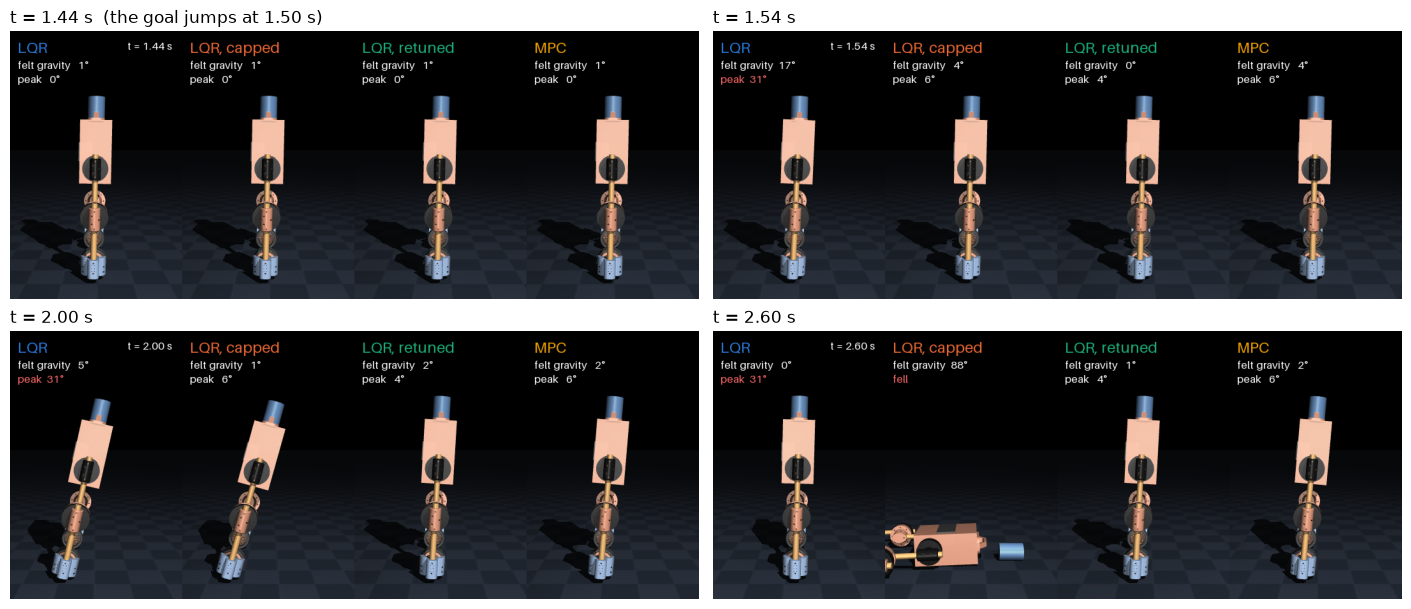

In [9]:
# The same film as still frames (for viewers that do not play videos)
if renderer is not None:
    fig, axes = plt.subplots(2, 2, figsize=(14, 6), constrained_layout=True)
    for ax, t in zip(axes.flat, (1.44, 1.54, 2.0, 2.6)):
        i = round((t - FILM_T0) * FILM_FPS)
        ax.imshow(video[i])
        ax.set_title(f"t = {FILM_T0 + i / FILM_FPS:.2f} s" + ("  (the goal jumps at 1.50 s)" if t < STEP_T else ""),
                     loc="left")
        ax.axis("off")
    plt.show()

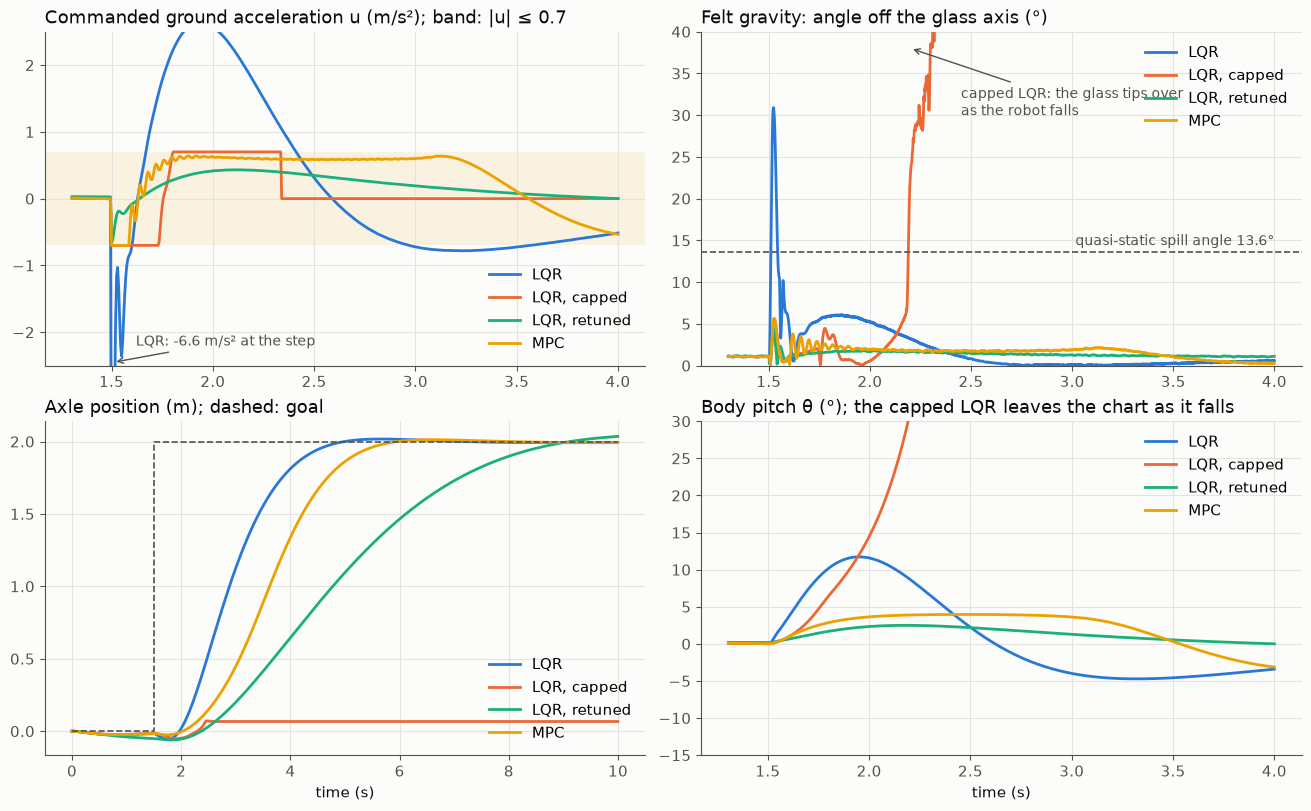

In [10]:
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11, "figure.facecolor": "#fcfcfb",
                     "axes.facecolor": "#fcfcfb", "legend.frameon": False})


fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
window = (1.3, 4.0)

ax = axes[0, 0]
ax.axhspan(-U_MAX, U_MAX, color="#eda100", alpha=0.10, lw=0)
for name, r in runs.items():
    keep = (r["t"] >= window[0]) & (r["t"] <= window[1])
    ax.plot(r["t"][keep], r["u"][keep], color=COLORS[name], lw=2, label=name)
ax.set_ylim(-2.5, 2.5)
ax.set_title("Commanded ground acceleration u (m/s²); band: |u| ≤ 0.7", loc="left", color=INK)
ax.annotate(f"LQR: {runs['LQR']['u'].min():.1f} m/s² at the step", xy=(STEP_T + 0.01, -2.45), xytext=(1.62, -2.2),
            color=MUTED, fontsize=10, arrowprops={"arrowstyle": "->", "color": MUTED})
ax.legend(loc="lower right")

ax = axes[0, 1]
for name, r in runs.items():
    keep = (r["tilt_t"] >= window[0]) & (r["tilt_t"] <= window[1])
    if r["fallen_t"] is not None:
        keep &= r["tilt_t"] < r["fallen_t"]
    ax.plot(r["tilt_t"][keep], r["tilt"][keep], color=COLORS[name], lw=2, label=name)
ax.axhline(SPILL_DEG, color=MUTED, lw=1.2, ls="--")
ax.text(window[1], SPILL_DEG + 0.8, f"quasi-static spill angle {SPILL_DEG:.1f}°", ha="right", color=MUTED, fontsize=10)
ax.set_ylim(0, 40)
ax.annotate("capped LQR: the glass tips over\nas the robot falls", xy=(2.2, 38), xytext=(2.45, 30), color=MUTED,
            fontsize=10, arrowprops={"arrowstyle": "->", "color": MUTED})
ax.set_title("Felt gravity: angle off the glass axis (°)", loc="left", color=INK)
ax.legend(loc="upper right")

ax = axes[1, 0]
for name, r in runs.items():
    ax.plot(r["t"], r["travel"], color=COLORS[name], lw=2, label=name)
ax.step([0, STEP_T, 10], [0, GOAL, GOAL], where="post", color=MUTED, lw=1.2, ls="--")
ax.set_title("Axle position (m); dashed: goal", loc="left", color=INK)
ax.set_xlabel("time (s)")
ax.legend(loc="lower right")

ax = axes[1, 1]
for name, r in runs.items():
    keep = (r["t"] >= window[0]) & (r["t"] <= window[1])
    ax.plot(r["t"][keep], r["pitch"][keep], color=COLORS[name], lw=2, label=name)
ax.set_ylim(-15, 30)
ax.set_title("Body pitch θ (°); the capped LQR leaves the chart as it falls", loc="left", color=INK)
ax.set_xlabel("time (s)")
ax.legend(loc="upper right")
plt.show()

## What the MPC knows that the capped LQR does not

The capped LQR computes the command of an unlimited robot, then clips it: it leans as if it could still accelerate
hard enough to catch itself, and it cannot. The MPC plans within the limit. At the instant of the step its whole
plan sits on the bound: a short kick back at −0.7 m/s², then +0.7 m/s² for the rest of the second, and the lean
that this push needs. It re-plans every 5 ms.

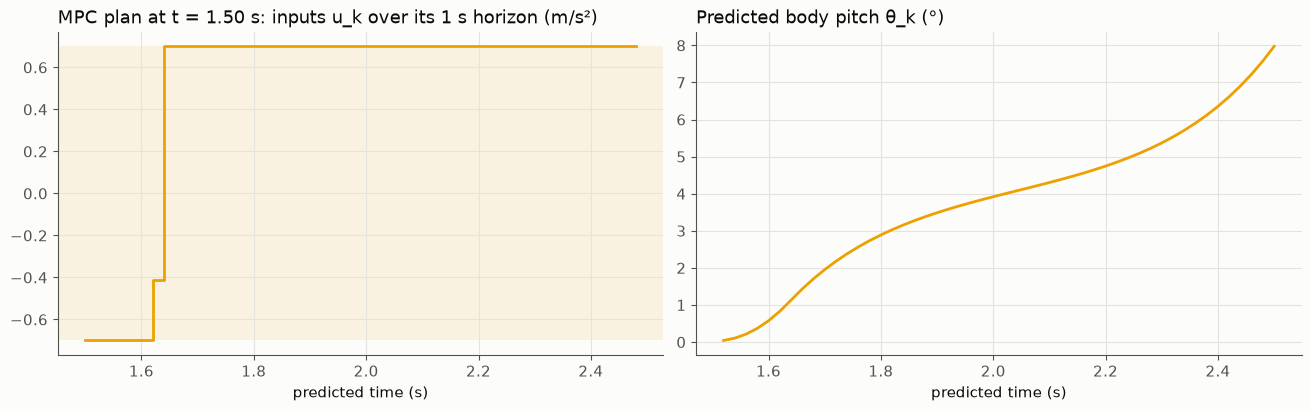

inputs at the bound: 49 of 50


In [11]:
t_plan, x_plan, (states, inputs) = runs["MPC"]["plan"]
horizon = t_plan + T * np.arange(1, len(inputs) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
ax1.axhspan(-U_MAX, U_MAX, color="#eda100", alpha=0.10, lw=0)
ax1.step(t_plan + T * np.arange(len(inputs)), inputs, where="post", color=COLORS["MPC"], lw=2)
ax1.set_title(f"MPC plan at t = {t_plan:.2f} s: inputs u_k over its 1 s horizon (m/s²)", loc="left", color=INK)
ax1.set_xlabel("predicted time (s)")
ax2.plot(horizon, np.degrees(states[:, 1]), color=COLORS["MPC"], lw=2)
ax2.set_title("Predicted body pitch θ_k (°)", loc="left", color=INK)
ax2.set_xlabel("predicted time (s)")
plt.show()
print(f"inputs at the bound: {np.sum(np.abs(np.abs(inputs) - U_MAX) < 1e-3)} of {len(inputs)}")

## Is the MPC just a capped LQR?

No. With no limit active anywhere in its plan, the MPC's first input is exactly the LQR law $-K(x - x_\mathrm{ref})$
(the terminal cost is the Riccati matrix). Below, the MPC's command next to what the LQR law would command from the
same state. The applied command touches the bound only at the kick, but the limit shapes every plan for 1.5 s
after the step, and the command is nothing like the LQR's until the plan no longer needs the bound.

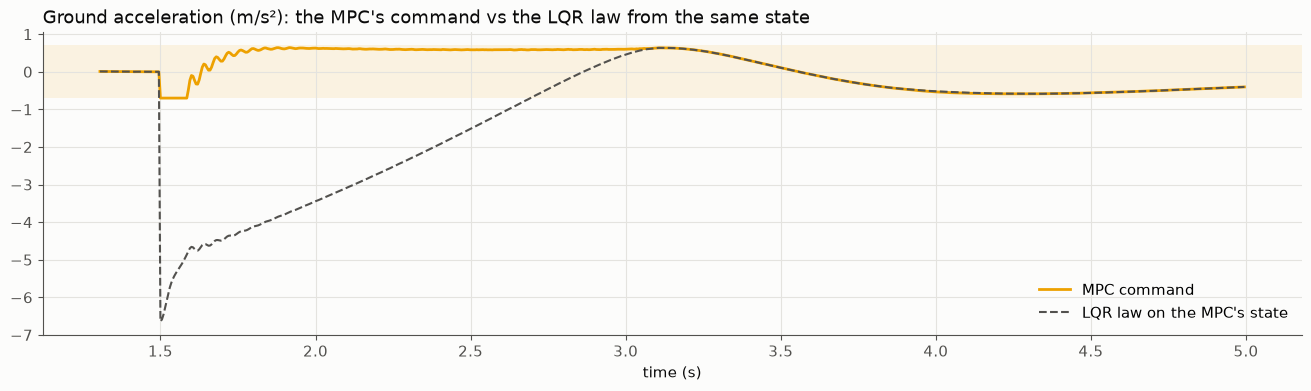

command at the bound: 90 ms; largest gap to the LQR law: 5.9 m/s²; within 0.15 m/s² of it from t = 3.00 s


In [12]:
r = runs["MPC"]
law = -((r["x"] - np.c_[r["goal"], np.zeros((len(r["t"]), 3))]) @ K[0])
keep = (r["t"] >= 1.3) & (r["t"] <= 5.0)
fig, ax = plt.subplots(figsize=(13, 3.8), constrained_layout=True)
ax.axhspan(-U_MAX, U_MAX, color="#eda100", alpha=0.10, lw=0)
ax.plot(r["t"][keep], r["u"][keep], color=COLORS["MPC"], lw=2, label="MPC command")
ax.plot(r["t"][keep], law[keep], color=MUTED, lw=1.5, ls="--", label="LQR law on the MPC's state")
ax.set_title("Ground acceleration (m/s²): the MPC's command vs the LQR law from the same state", loc="left", color=INK)
ax.set_xlabel("time (s)")
ax.legend(loc="lower right")
plt.show()
gap, after = np.abs(r["u"] - law), r["goal"] > 0
last_apart = np.nonzero(after & (gap >= 0.15))[0][-1]
print(f"command at the bound: {np.sum(after & (np.abs(r['u']) >= U_MAX - 1e-3)) * CONTROL_EVERY * DT * 1000:.0f} ms; "
      f"largest gap to the LQR law: {gap[after].max():.1f} m/s²; "
      f"within 0.15 m/s² of it from t = {r['t'][last_apart + 1]:.2f} s")

## Limits and credits

- The water is not simulated (a rigid glass of 0.35 kg): the tilt of the gravity it would feel is the measure of a
  spill.
- The linear model ignores the legs' and wheels' dynamics; the MuJoCo robot does not. Both controllers use the same
  model, the same $Q$ and $R$ and the same goal; the MPC does not see the step coming (no preview).
- Upkie: [upkie/upkie](https://github.com/upkie/upkie), robot model
  [upkie/upkie_description](https://github.com/upkie/upkie_description) by Stéphane Caron and contributors
  (Apache-2.0; wheel tyre mesh by bramesh501, CC BY 4.0). Our balancers follow Upkie's own (wheeled inverted
  pendulum, MPC balancer), reimplemented here.
- OSQP: B. Stellato, G. Banjac, P. Goulart, A. Bemporad, S. Boyd, *OSQP: an operator splitting solver for quadratic
  programs*, Mathematical Programming Computation, 2020.
- This notebook: Apache-2.0.